In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters

In [ ]:
array_length = 128 #elements
pitch = 0.110e-3 #m
frequency = 1.5e+7 #hz
c = 1500 #m/s
sampling_rate = 16 * frequency  #hz

object_depth = 3e-3 #m
object_position = 7e-3 #m

object2_depth = 4e-3 #m
object2_position = 8e-3 #m

object3_depth = 3.1e-3 #m
object3_position = 7.5e-3 #m

total_depth = 1e-2 #m

step_size = total_depth / c #s
samples = int(sampling_rate * step_size)

pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #position sampling
time = np.linspace(start=0, stop=step_size, num=samples) #time sampling

print("Samples: ", samples)
print("Step size: ", step_size, "µs")

Samples:  1600
Step size:  6.666666666666667e-06 µs


## Objects

In [4]:
class Objects:
    def __init__(self, depth, position):
        self.depth = depth
        self.position = position
        self.delays = np.zeros(array_length)
        self.rf_matrix = np.zeros((samples, array_length))

In [5]:
objects = [Objects(object_depth, object_position), Objects(object2_depth, object2_position), Objects(object3_depth, object3_position)]
obj_nbr = len(objects)

# Signals

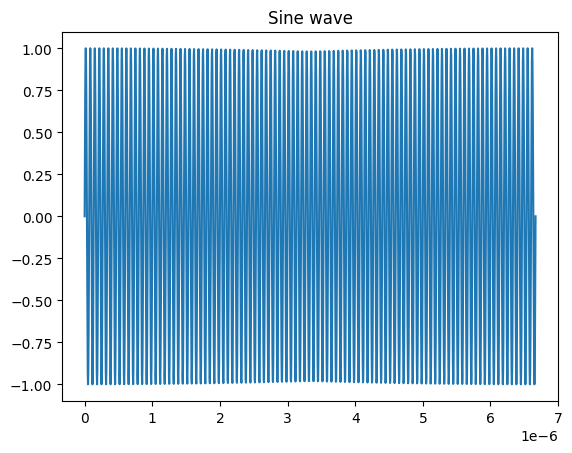

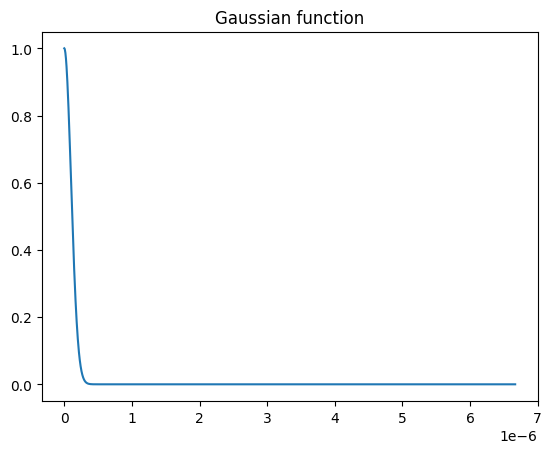

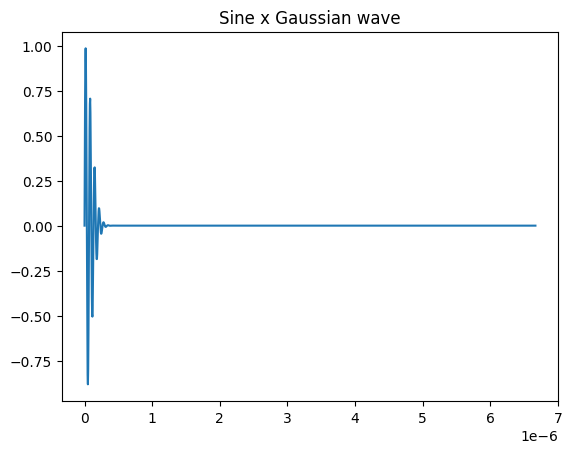

In [6]:
gaussian_std = 0.0000001

def sine_wave(frequency, timestep):
    return np.sin(2*np.pi*frequency*timestep )#+ np.pi/2)

def gaussian_function(timestep, std):
    return np.exp(-timestep**2 / (2 * std**2))

def generate_wave(frequency, timestep, std):
    return sine_wave(frequency, timestep) * gaussian_function(timestep, std)

wave = sine_wave(frequency, time)
plt.plot(time, wave)
plt.title("Sine wave")
plt.show()

wave = gaussian_function(time, gaussian_std)
plt.plot(time, wave)
plt.title("Gaussian function")
plt.show()

wave = generate_wave(frequency, time, gaussian_std)
plt.plot(time, wave)
plt.title("Sine x Gaussian wave")
plt.show()

# DAS (delay and sum)

In [7]:
def delay_function(object_depth, object_position, speed_sound, array_position, pitch):
    return (object_depth / speed_sound) + np.sqrt(object_depth**2 + (array_position * pitch - object_position)**2) / speed_sound

In [8]:
delays = np.zeros(array_length)

for i in range(0, obj_nbr):
    for j in range(0, array_length):
        objects[i].delays[j] = delay_function(object_depth=objects[i].depth, object_position=objects[i].position, speed_sound=c, array_position=j, pitch=pitch)
        delays[j] += objects[i].delays[j]

## Showing delay results

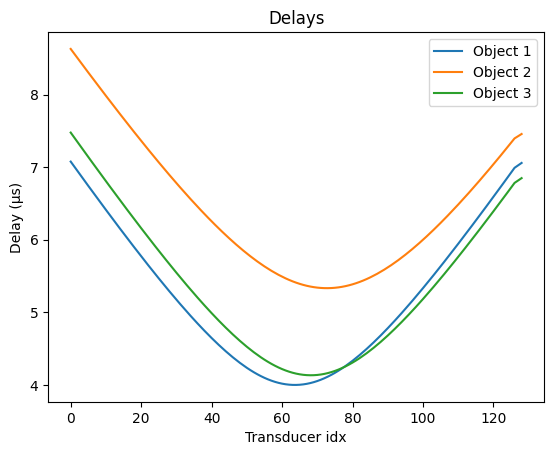

In [9]:
plt.figure()    
for i in range(0, obj_nbr):
    plt.plot(pos, objects[i].delays*1e6, label = f"Object {i+1}")
plt.title("Delays")
plt.xlabel("Transducer idx")
plt.ylabel("Delay (µs)")
plt.legend()
plt.show()

## Showing sum of delays

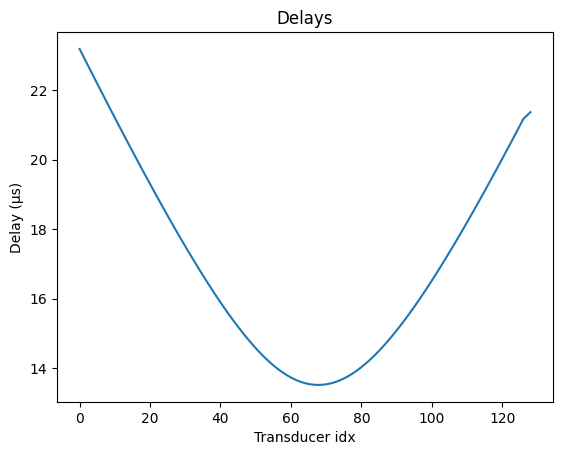

In [10]:
plt.figure()    
plt.plot(pos, delays*1e6)
plt.title("Delays")
plt.xlabel("Transducer idx")
plt.ylabel("Delay (µs)")
plt.show()

## Adding Wave

In [11]:
rf_matrix_summed = np.zeros((samples, array_length))

for i in range(0, obj_nbr):
    for j in range(array_length):
        #for each transducer, generate the wave with the corresponding delay
        objects[i].rf_matrix[:, j] = generate_wave(frequency, time - objects[i].delays[j], gaussian_std)
            
        rf_matrix_summed[:,j] += objects[i].rf_matrix[:,j]

## Showing wave results

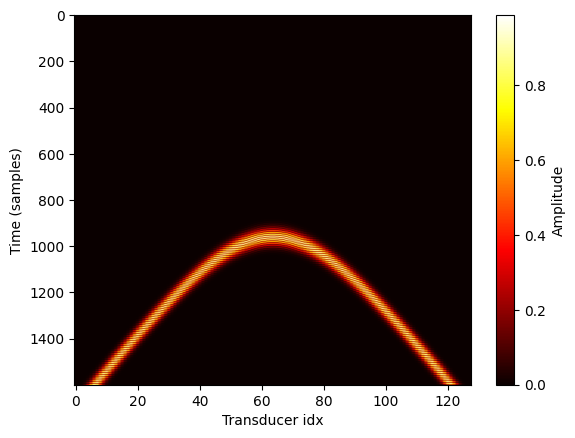

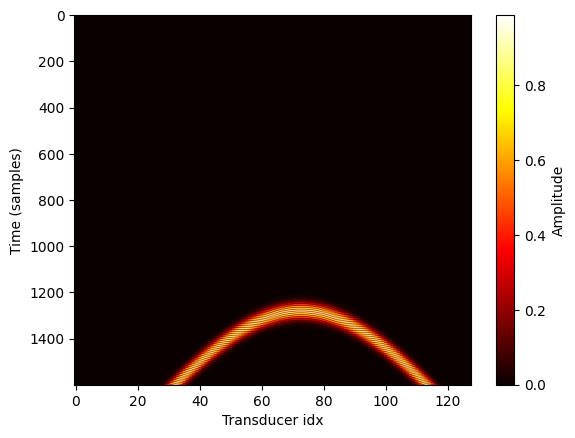

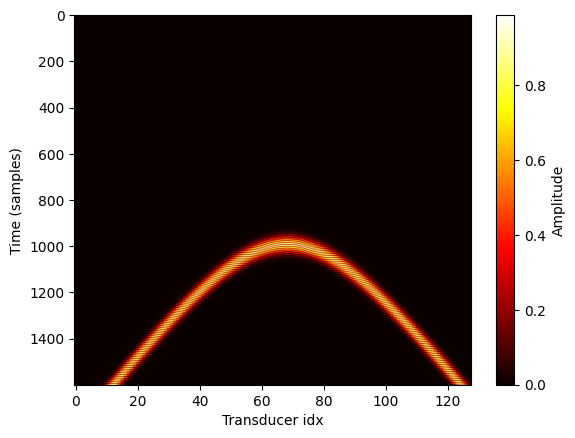

In [12]:
for i in range(0, obj_nbr):
    objects[i].rf_matrix.tofile(f"./data/csv/rf_matrix_object{i+1}.csv", sep=",")
    plt.figure()
    plt.imshow(abs(objects[i].rf_matrix), cmap='hot', aspect='auto')
    plt.xlabel("Transducer idx")
    plt.ylabel("Time (samples)")
    plt.savefig(f"./data/images/rf_matrix_object{i+1}.png")
    plt.colorbar(label="Amplitude")
    plt.show()

## Showing summed wave results

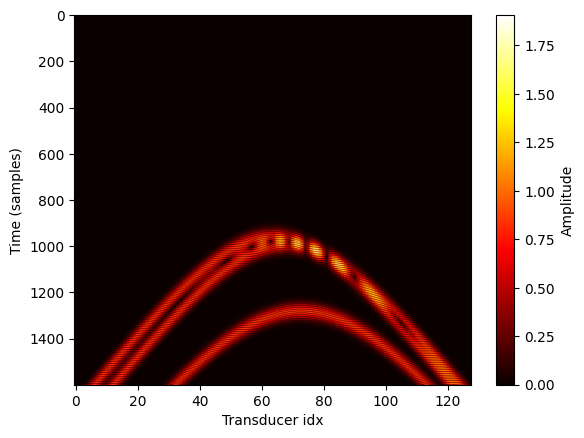

In [13]:
rf_matrix_summed.tofile(f"./data/csv/rf_matrix_summed.csv", sep=",")
plt.imshow(abs(rf_matrix_summed), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.savefig("./data/images/rf_matrix_summed.png")
plt.colorbar(label="Amplitude")
plt.show()

## Applying sum

In [ ]:
bf_matrix = np.zeros((samples, array_length))
total_depth_sample = total_depth / samples  #total depth in m / number of samples = depth per sample

for j in range(0, array_length):
    for k in range(0, samples):

        depth = total_depth_sample*k
        position = pitch*j

        for l in range(0, array_length):

            delay = delay_function(object_depth=depth, object_position=position, speed_sound=c, array_position=l, pitch=pitch)
            delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)

            if delay_idx < samples:
                bf_matrix[k,j] += rf_matrix_summed[delay_idx, l] #we take sample in calculated rf_matrix (faster than recalculating)

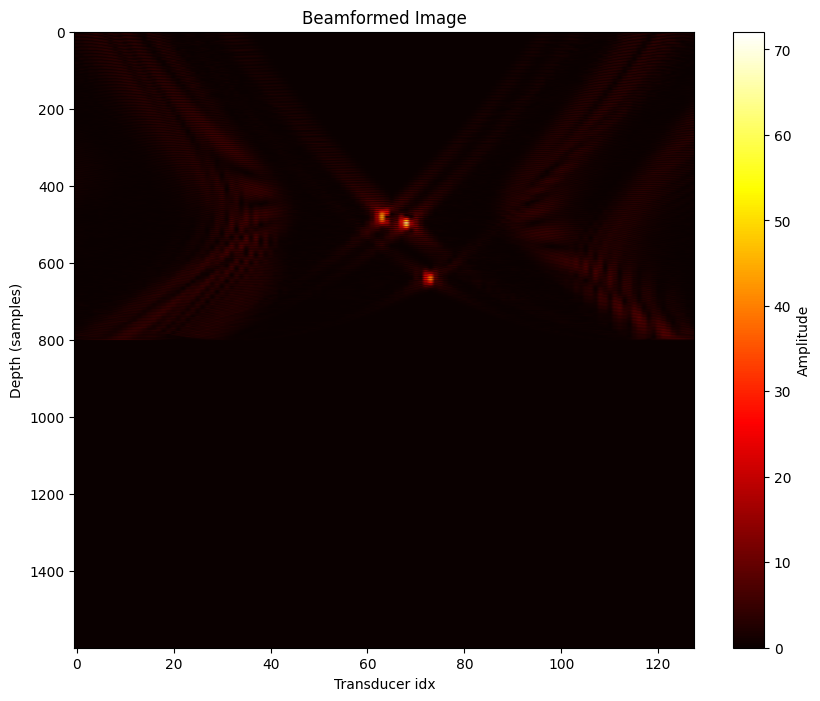

In [15]:
bf_matrix.tofile(f"./data/csv/bf_matrix.csv", sep=",")
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix), cmap='hot', aspect='auto')
plt.title("Beamformed Image")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data/images/bf_image.png")
plt.show()

# Explanation

## The Core Concept
The key insight is that if there was a **reflector at the pixel location:**
- Each transducer would have received a reflection at a specific delay time
- By looking up what was actually measured at those specific delay times
- And adding them together
- We get constructive interference where actual reflectors exist

This is the fundamental principle behind delay-and-sum beamforming.
When we align and sum the signals properly, reflections from real objects add constructively, while noise tends to cancel out.

Example Scenario:

Imagine a reflector at depth 5mm:

- For a centered transducer, the echo might arrive at 6.67 μs (5mm ÷ 1500 m/s × 2)
- For an off-center transducer, it would take slightly longer due to the diagonal path
- When we sum the signals at their correct delay times, the reflector "appears" in our image
- This technique essentially transforms time-domain signals into a spatial image, revealing the locations of reflectors in your imaging field